<div align="center"><img src="https://github.com/user-attachments/assets/5d3a38ab-b20c-4103-b401-cddc112bfac8" width="300" alt="NOVA IMS Logo">

  <br>
  <br>
  <b>Master in Data Science and Advanced Analytics</b>

  <b>Computational Intelligence for Optimization </b>

  2025–2026

  <h1><b> Vermeer’s <i>Girl with a pearl earing</i>: 100 triangles Challenge <b></h1>
</div>



### <span style="color:#86A3BC;">C22_Natural_Selection | Members</span>

<table>
  <thead style="color:#86A3BC;">
    <tr>
      <th>Name</th>
      <th>Student ID</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td>Afonso Hermenegildo</td>
      <td>20221958</td>
    </tr>
    <tr>
      <td>André Ferreira</td>
      <td>20250398</td>
    </tr>
    <tr>
      <td>Marco Martins</td>
      <td>20221951</td>
    </tr>
    <tr>
      <td>Maria Francisca Gonçalves</td>
      <td>20221942</td>
    </tr>
  </tbody>
</table>

## <span style="color:#86A3BC;">Table of Contents</span>


[ADICIONAR!!]

# <span id="chapter1" style="color:#86A3BC;">1. Imports</span>

<p><a href="#toc" style="color:#86A3BC;"> Back to Table of Contents</a></p>

All libraries used throughout the notebook are imported here. We rely on `Pillow` and `numpy` for image handling, `matplotlib` for visualisation, and `scipy` for statistical testing. The class-provided `library` module is also imported to access the base `Solution` class.

In [200]:
import sys, os
sys.path.insert(0, os.path.join(os.getcwd(), "scripts"))

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

from functools import partial # pass a pre-applied selector via functools.partial.
from copy import deepcopy

from scripts.triangle_sol import TriangleSolution, AdaptiveMutationRateTriangleSolution
from scripts.ga import genetic_algorithm
from scripts.ga_utils import get_fitness
from scripts.experiments import plot_fitness_history
from scripts.new_hill_climbing import hill_climbing, plot_hill_climbing_log
from operators import (
    # selection
    roulette_wheel_selection,
    rank_based_selection,
    tournament_selection,
    # crossover
    one_point_crossover,
    two_point_crossover,
    uniform_crossover,
    geometric_crossover,
    # mutation
    triangle_gaussian_mutation,
    triangle_gaussian_color_mutation,
    triangle_gaussian_vertex_mutation,
    triangle_reset_gene_mutation,
    triangle_reset_mutation,
    triangle_layer_swap_mutation,
    geometric_mutation,
    # new fitness sharing
    representation_vectors,
    sharing_function,
    compute_counts,
    apply_fitness_sharing, 
    fitness_sharing_selection, 
    measure_diversity,
    AutomaticFitnessSharingSelection,
    AdvancedFitnessSharingSelection,
    GenerationCounterCallback,
    population_diversity_report
)
from scripts.statistical_comparison import (
    run_ga_statistical_comparison,
    plot_statistical_comparison,
    run_statistical_test,
    run_multi_group_statistical_test,
    save_statistical_results,
    load_statistical_results,
    plot_statistical_comparison_interactive,
    cross_evaluate_results,
    cross_eval_table,
    plot_image_comparison,
    plot_diversity_statistical_comparison_interactive
)
from scripts.perceptual_fitness import (
    PerceptualTriangleSolution,
    set_perceptual_target,
    rmse_score,
    perceptual_score
)
from scripts.perceptual_comparison import (
    run_paired_comparison,
    wilcoxon_tests,
    plot_convergence,
    plot_metric_distributions,
)

# <span id="chapter2" style="color:#86A3BC;">2. Target Image Loading &amp; Inspection</span>

<p><a href="#toc" style="color:#86A3BC;"> Back to Table of Contents</a></p>

We load the 300×400 target image and convert it to a NumPy array. Keeping the array in memory as a global constant avoids redundant I/O during fitness evaluations, which are called thousands of times per run.

Image size  : 300 x 400 px
Array shape : (400, 300, 4)


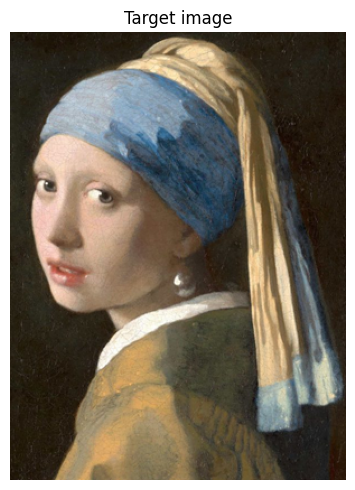

In [2]:
IMG_PATH = "project_info/girl_pearl_earing.png"

target_img = Image.open(IMG_PATH).convert("RGBA")
target_arr = np.array(target_img, dtype=np.float32)

IMG_WIDTH, IMG_HEIGHT = target_img.size   # (width, height) from PIL

print(f"Image size  : {IMG_WIDTH} x {IMG_HEIGHT} px")
print(f"Array shape : {target_arr.shape}")

# Pass the target to TriangleSolution so every instance uses it automatically
TriangleSolution.target_array = target_arr

plt.figure(figsize=(4, 5))
plt.imshow(target_arr / 255)
plt.title("Target image")
plt.axis("off")
plt.tight_layout()
plt.show()

# <span id="chapter3" style="color:#86A3BC;">3. Solution Representation</span>

<p><a href="#toc" style="color:#86A3BC;">Back to Table of Contents</a></p>

### Representation - How the solution is encoded

Each individual in the population encodes a candidate image as an ordered sequence of **100 triangles**, drawn sequentially onto a 300×400 canvas — later triangles occlude earlier ones. Each triangle is represented by **10 real-valued genes**.

```
[ x1, y1, x2, y2, x3, y3, Red, Green, Blue, Alpha]
```


| Gene(s) | Variable | Domain |
|---|---|---|
| x₁, y₁, x₂, y₂, x₃, y₃ | Vertex coordinates | [0, 1] (normalised) |
| R, G, B | Fill colour | [0, 255] |
| A | Opacity | [0, 255] |

### Fitness - measurement of quality of the solution
Fitness is the **pixel-wise RMSE** between the rendered image and the target (lower is  better, since this is a minimisation problem):

$$\text{RMSE} = \sqrt{\frac{1}{W \cdot H \cdot 4} \sum_{i,j,c} (\hat{I}_{ijc} - I_{ijc})^2}$$

where $W=300$, $H=400$, and $C=4$ (RGBA channels)

In [4]:
sol = TriangleSolution()

In [5]:
sol = TriangleSolution()
sol.representation

array([ 39.,  15., 226., 385., 166.,  62., 207., 199.,  55., 144., 110.,
       163., 221., 143.,  28., 258.,  67.,  73., 219., 185.,  45., 190.,
       230., 234., 292., 257., 210., 156., 209.,  71., 138., 166., 138.,
       374.,  42., 210., 158.,  77., 252.,  79., 103., 213., 118., 227.,
       168., 100.,  18., 170., 228., 112.,  12., 175., 227., 301.,  65.,
       228., 216., 152.,  94.,  20.,  17., 266.,  39., 344., 234., 397.,
       166., 198., 160., 157.,  59.,   6.,  96., 282., 163., 387., 175.,
       105., 249., 160., 161., 104.,  97.,  74., 210., 302.,  89., 217.,
        87.,  20.,   8., 238., 266., 262., 184., 219.,  28., 110., 216.,
       228., 279., 294., 140., 105.,  67., 147., 228., 118., 137.,  79.,
       257., 370., 213., 257.,   3., 235.,  33., 185., 117., 191.,  41.,
       365.,  63., 182., 168., 343.,  86., 187.,  23., 206.,  16., 270.,
       211., 127.,  49., 331.,  48., 147., 107., 132.,  28., 265., 284.,
       109.,  91., 290., 183., 186., 123.,  81., 25

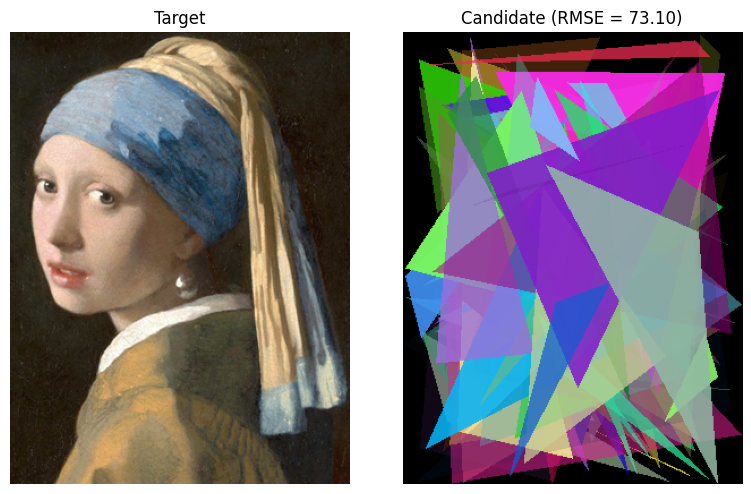

In [6]:
sol.show()

The output generated is a **single random individual**.

# <span id="chapter4" style="color:#86A3BC;">4. Baseline GA Run</span>

<p><a href="#toc" style="color:#86A3BC;">Back to Table of Contents</a></p>

A single run with sensible defaults to confirm everything works end-to-end.

In [3]:
best_sol, history, avg_history = genetic_algorithm(
    population_size = 50,
    n_generations = 200,
    selection_function = tournament_selection,
    crossover_function = one_point_crossover,
    mutation_function = triangle_gaussian_mutation,
    crossover_rate = 0.9,
    mutation_rate = 0.02,
    mutation_rate_decay = None,
    elitism_n = 2,
    n_jobs = -1,
    verbose = True,
    verbose_every = 25
)
print(f"Best RMSE : {get_fitness(best_sol):.4f}")

Gen    0 | best RMSE: 61.4989 | avg RMSE: 66.7370 | mut rate: 0.02000
Gen   25 | best RMSE: 51.8284 | avg RMSE: 52.2657 | mut rate: 0.02000
Gen   50 | best RMSE: 49.2519 | avg RMSE: 49.6504 | mut rate: 0.02000
Gen   75 | best RMSE: 47.4375 | avg RMSE: 47.7246 | mut rate: 0.02000
Gen  100 | best RMSE: 45.7331 | avg RMSE: 45.9751 | mut rate: 0.02000
Gen  125 | best RMSE: 44.3684 | avg RMSE: 44.6198 | mut rate: 0.02000
Gen  150 | best RMSE: 42.8598 | avg RMSE: 43.2923 | mut rate: 0.02000
Gen  175 | best RMSE: 41.8822 | avg RMSE: 42.0743 | mut rate: 0.02000
Gen  199 | best RMSE: 40.9549 | avg RMSE: 41.1617 | mut rate: 0.02000

Finished. Best RMSE: 40.9549
Best RMSE : 40.9549


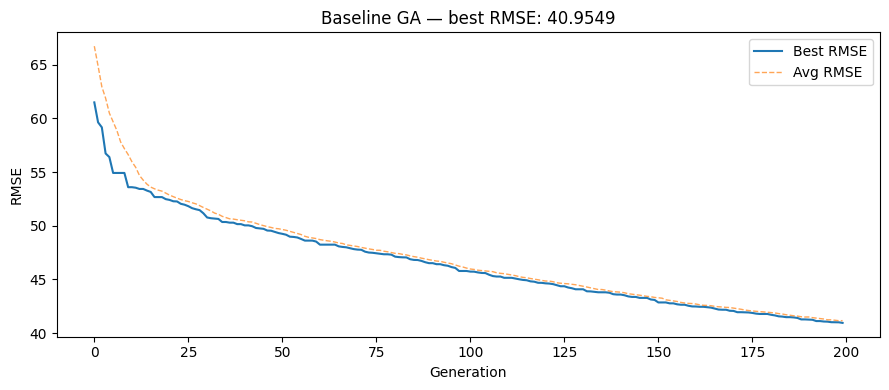

In [4]:
plot_fitness_history(
    history,
    avg_history,
    title=f"Baseline GA — best RMSE: {history[-1]:.4f}",
)

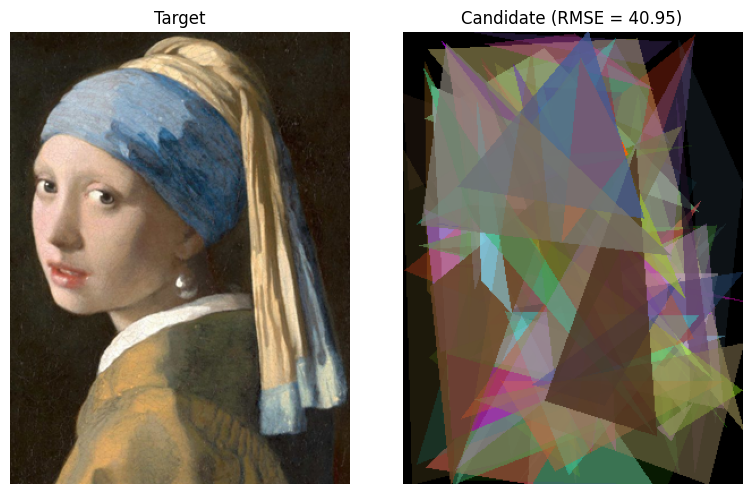

In [5]:
best_sol.show()

# <span id="chapter5" style="color:#86A3BC;">5. Genetic Operators</span>

<p><a href="#toc" style="color:#86A3BC;">Back to Table of Contents</a></p>

This section defines the genetic operators implemented for the triangle-image representation. The next section then compares these alternatives empirically and selects the operators and hyperparameters used in the final run.

### Selection

Selection chooses parents based on fitness. Because this is a minimization problem, lower RMSE corresponds to better fitness.

- **[Roulette-wheel selection](operators/selection.py#L5):** uses inverted RMSE values so lower-error individuals have higher selection probability.
- **[Rank-based selection](operators/selection.py#L20):** assigns probabilities according to sorted rank rather than raw RMSE differences.
- **[Tournament selection](operators/selection.py#L36):** samples a subset of individuals and selects the best one; the tournament size controls selection pressure.
- **[Fitness sharing](operators/new_fitness_sharing.py#L86):** adjusts fitness during selection by penalizing individuals in crowded regions of the genotype space.

### Crossover

Crossover recombines parent genotypes. Since each group of genes defines a complete triangle, most crossover operators preserve triangle boundaries instead of splitting inside a triangle.

- **[One-point crossover](operators/crossover.py#L7):** swaps the suffix of two parents after a randomly chosen triangle boundary.
- **[Two-point crossover](operators/crossover.py#L35):** swaps a middle segment between two triangle-boundary cut points.
- **[Uniform crossover](operators/crossover.py#L72):** independently chooses, for each triangle position, which parent contributes that triangle.
- **[Geometric crossover](operators/crossover.py#L107):** creates one real-valued offspring by taking weighted combinations of parent genes and clipping them to valid coordinate and colour ranges.

### Mutation

Mutation introduces new variation by modifying existing individuals. The representation is bounded and mostly continuous, so mutation operators either perturb genes locally or reset parts of the representation.

- **[Gaussian mutation](operators/mutation.py#L6):** adds normally distributed noise to vertex and RGBA genes.
- **[Color-only Gaussian mutation](operators/mutation.py#L61):** changes only RGBA values.
- **[Vertex-only Gaussian mutation](operators/mutation.py#L100):** changes only triangle coordinates.
- **[Per-gene reset mutation](operators/mutation.py#L142):** randomly resets individual genes.
- **[Per-triangle reset mutation](operators/mutation.py#L183):** replaces complete triangles.
- **[Layer-swap mutation](operators/mutation.py#L227):** swaps two triangles in the drawing order, changing occlusion without changing shape or colour.
- **[Geometric mutation](operators/mutation.py#L274):** applies bounded uniform perturbations, following the box-mutation idea for continuous optimization.

# <span id="chapter6" style="color:#86A3BC;">6. Statistical Tests</span>

<p><a href="#toc" style="color:#86A3BC;">Back to Table of Contents</a></p>

All operator and hyperparameter choices in this project were validated with **repeated independent runs** (30 per configuration) to account for randomness. Results are compared using:
- **Normality check** first (Shapiro-Wilk test).
- **Welch's t-test** if both samples are approximately normal.
- **Mann-Whitney U test** for independent non-normal samples.
- **Significance level: α = 0.05.**

Convergence plots show the average best RMSE over cumulative evaluations, with ±1 standard deviation bands.

## <span id="chapter6.1" style="color:#86A3BC;">6.1 Selection</span>

**What was tested:** Six selection strategies were compared across 30 runs each:
- Roulette-wheel selection
- Rank-based selection
- Tournament selection with sizes: 2, 3, 5, 10

A follow-up experiment tested even higher pressures with tournament sizes: 15, 20, and 30.

In [ ]:
# selection_statistical_comparison = run_ga_statistical_comparison(
#     "selection_function",
#     [
#         roulette_wheel_selection,
#         rank_based_selection,
#         tournament_selection, # default tournament size is 2
#         lambda p: tournament_selection(p, tournament_size=3),
#         lambda p: tournament_selection(p, tournament_size=5),
#         lambda p: tournament_selection(p, tournament_size=10),
#     ]
# )


Starting statistical comparison: 180 GA runs, 1,800,000 total evaluations



Progress: 100%|██████████| 1800000/1800000 [39:46<00:00, 754.17 evaluation/s] 


In [ ]:
# save_statistical_results(
#     selection_statistical_comparison,
#     "results/selection_statistical_comparison.pkl"
# )

In [ ]:
selection_statistical_comparison = load_statistical_results("results/selection_statistical_comparison.pkl")

In [169]:
selection_functions = [
    "Roullete-wheel",
    "Rank-based",
    "Tournament (2)",
    "Tournament (3)",
    "Tournament (5)",
    "Tournament (10)"
]

plot_statistical_comparison_interactive(
    selection_statistical_comparison,
    labels=selection_functions,
    title="Selection Operator Comparison — Statistical Results (30 runs each, shaded areas = ±1 std dev)",
)

In [170]:
run_multi_group_statistical_test(
    selection_statistical_comparison,
    names=selection_functions,
    paired=False
)

=== Normality Checks (Shapiro-Wilk) ===
  - Roullete-wheel                 p-value: 0.6549 (Normal: True)
  - Rank-based                     p-value: 0.5071 (Normal: True)
  - Tournament (2)                 p-value: 0.1841 (Normal: True)
  - Tournament (3)                 p-value: 0.8314 (Normal: True)
  - Tournament (5)                 p-value: 0.6224 (Normal: True)
  - Tournament (10)                p-value: 0.0031 (Normal: False)

=== Omnibus Statistical Test ===
At least one group is non-normal. Running Kruskal-Wallis H-test...
Omnibus test used: Kruskal-Wallis H-test
p-value: 0.000000

=== Summary Statistics ===
  - Roullete-wheel                 Mean: 46.8558 | Median: 46.6772 | Std: 1.5690
  - Rank-based                     Mean: 39.4332 | Median: 39.1865 | Std: 0.9154
  - Tournament (2)                 Mean: 39.9268 | Median: 39.8223 | Std: 0.9878
  - Tournament (3)                 Mean: 37.7290 | Median: 37.7435 | Std: 1.1011
  - Tournament (5)                 Mean: 37.2566 | 

Results show consistent improvements as tournament size increased up to 10, with no clear sign of plateauing. This prompted a follow-up experiment to check if even higher selection pressures would yield further gains.

In [ ]:
# selection_statistical_comparison2 = run_ga_statistical_comparison(
#     "selection_function",
#     [
#         lambda p: tournament_selection(p, tournament_size=15),
#         lambda p: tournament_selection(p, tournament_size=20),
#         lambda p: tournament_selection(p, tournament_size=30),
#     ]
# )


Starting statistical comparison: 90 GA runs, 900,000 total evaluations



Progress: 100%|██████████| 900000/900000 [20:35<00:00, 728.66 evaluation/s] 


In [ ]:
# save_statistical_results(
#     selection_statistical_comparison2,
#     "results/selection_statistical_comparison2.pkl"
# )

In [ ]:
selection_statistical_comparison2 = load_statistical_results("results/selection_statistical_comparison2.pkl")

In [ ]:
selection_functions2 = [
    "Tournament selection (15)",
    "Tournament selection (20)",
    "Tournament selection (30)",
]

plot_statistical_comparison_interactive(
    selection_statistical_comparison2,
    labels=selection_functions2,
    title="Selection Operator Comparison — Statistical Results (30 runs each, shaded areas = ±1 std dev)",
)

In [166]:
run_multi_group_statistical_test(
    selection_statistical_comparison2,
    names=selection_functions2,
    paired=False
)

=== Normality Checks (Shapiro-Wilk) ===
  - Tournament selection (15)      p-value: 0.5560 (Normal: True)
  - Tournament selection (20)      p-value: 0.4966 (Normal: True)
  - Tournament selection (30)      p-value: 0.4542 (Normal: True)

=== Omnibus Statistical Test ===
All groups are approximately normal. Running One-way ANOVA...
Omnibus test used: One-way ANOVA
p-value: 0.121096

=== Summary Statistics ===
  - Tournament selection (15)      Mean: 35.7456 | Median: 35.7718 | Std: 0.9029
  - Tournament selection (20)      Mean: 35.3581 | Median: 35.5935 | Std: 1.1042
  - Tournament selection (30)      Mean: 35.2192 | Median: 35.0264 | Std: 0.9789

Omnibus test is NOT statistically significant (p >= alpha).
No post-hoc pairwise comparisons will be performed.


All of the values are statistically equivalent.

**Key findings:**
- Higher tournament sizes generally led to faster initial convergence.
- All large tournament sizes (10–30) produced results that were very close to each other, overlapping within their standard deviation bands, with no statistically significant difference between them.

**Final choice:** **Tournament selection with tournament size 10** — balances selection pressure with population diversity, and is easy to tune.

## <span id="chapter6.2" style="color:#86A3BC;">6.2. Crossover</span>

**What was tested:** Four crossover operators were compared across 30 runs each:
- One-point crossover
- Two-point crossover
- Uniform crossover
- Geometric crossover *(returns one offspring)*

In [ ]:
# crossover_statistical_comparison = run_ga_statistical_comparison(
#     "crossover_function",
#     [
#         one_point_crossover,
#         two_point_crossover,
#         uniform_crossover,
#         geometric_crossover
#     ]
# )


Starting statistical comparison: 120 GA runs, 1,200,000 total evaluations



Progress: 100%|██████████| 1200000/1200000 [28:40<00:00, 697.62 evaluation/s]


In [ ]:
# save_statistical_results(
#     crossover_statistical_comparison,
#     "results/crossover_statistical_comparison.pkl"
# )

In [ ]:
crossover_statistical_comparison = load_statistical_results("results/crossover_statistical_comparison.pkl")

In [25]:
crossover_functions = [
    "One point",
    "Two point",
    "Uniform",
    "Geometric"
]

plot_statistical_comparison_interactive(
    crossover_statistical_comparison,
    labels=crossover_functions,
    title="Crossover Operator Comparison — Statistical Results (30 runs each, shaded areas = ±1 std dev)",
)

Results show a clear separation between uniform crossover and both one-point and two-point crossover, so we will do statistical tests only between these operators.

In [171]:
run_multi_group_statistical_test(
    crossover_statistical_comparison,
    names=crossover_functions,
    paired=False
)

=== Normality Checks (Shapiro-Wilk) ===
  - One point                      p-value: 0.0673 (Normal: True)
  - Two point                      p-value: 0.1344 (Normal: True)
  - Uniform                        p-value: 0.4994 (Normal: True)
  - Geometric                      p-value: 0.6705 (Normal: True)

=== Omnibus Statistical Test ===
All groups are approximately normal. Running One-way ANOVA...
Omnibus test used: One-way ANOVA
p-value: 0.000000

=== Summary Statistics ===
  - One point                      Mean: 39.3977 | Median: 39.6086 | Std: 0.9437
  - Two point                      Mean: 38.6256 | Median: 38.4263 | Std: 1.1472
  - Uniform                        Mean: 35.3656 | Median: 35.3403 | Std: 0.9951
  - Geometric                      Mean: 45.8741 | Median: 45.8689 | Std: 1.2300

Omnibus test is statistically significant (p < alpha)!
Performing post-hoc pairwise comparisons with Holm-Bonferroni correction...

Comparison                                         | Test Used  

**Key findings:**
- **Uniform crossover significantly outperformed** one-point and two-point crossover:
  - One-point vs. Uniform: Welch t-test, p = 0.0000 → mean RMSE 39.6114 vs. 35.4099
  - Two-point vs. Uniform: Welch t-test, p = 0.0000 → mean RMSE 38.7940 vs. 35.4099

### Crossover rate

In [ ]:
# crossover_rate_statistical_comparison = run_ga_statistical_comparison(
#     "crossover_rate",
#     [
#         0.90,
#         0.80,
#         0.70,
#         0.50,
#         0.30
#     ],
#     fixed_params={
#         "crossover_function": uniform_crossover
#     }
# )


Starting statistical comparison: 150 GA runs, 1,500,000 total evaluations



Progress: 100%|██████████| 1500000/1500000 [35:13<00:00, 709.80 evaluation/s]


In [ ]:
# save_statistical_results(
#     crossover_rate_statistical_comparison,
#     "results/crossover_rate_statistical_comparison.pkl"
# )

In [121]:
crossover_rate_statistical_comparison = load_statistical_results("results/crossover_rate_statistical_comparison.pkl")

In [122]:
crossover_rates = [
    "0.90",
    "0.80",
    "0.70",
    "0.50",
    "0.30"
]

plot_statistical_comparison_interactive(
    crossover_rate_statistical_comparison,
    labels=crossover_rates,
    title="Crossover Rate Comparison — Statistical Results (30 runs each, shaded areas = ±1 std dev)",
)

In [126]:
# statistical tests between two best values - 0.90 e 0.80
run_statistical_test(
    crossover_rate_statistical_comparison[0.90]["best_per_run"],
    crossover_rate_statistical_comparison[0.80]["best_per_run"],
    name_a="0.90",
    name_b="0.80",
    paired=False
)

0.90 normality p-value: 0.1185
0.80 normality p-value: 0.0212

Mann-Whitney U / Wilcoxon rank-sum test
p-value: 0.0032

0.90 mean final RMSE: 34.9475
0.80 mean final RMSE: 35.8176
Difference is statistically significant.


**Key findings:**
- Among crossover rates, **0.90** produced the best results:
  - 0.90 vs. 0.80: Welch t-test, p = 0.0032 → mean RMSE 34.9475 vs. 35.8176

**Final choice:** **Uniform crossover** at a crossover rate of **0.90**.

## <span id="chapter6.3" style="color:#86A3BC;">6.3. Mutation</span>

### <span id="chapter6.3.1" style="color:#86A3BC;">6.3.1. Mutation operator</span>

**What was tested:** Seven mutation operators were compared across 30 runs each:
- Gaussian (full) - perturbs all 10 genes of each selected triangle
- Gaussian (color) - perturbs only the RGBA color channels
- Gaussian (vertex) - perturbs only the vertex coordinates
- Reset per-gene - randomly resets individual genes
- Reset per-triangle - randomly resets entire triangles
- Layer swap - swaps the rendering order of triangles
- Geometric mutation - bounded uniform perturbation

In [127]:
# mutation_statistical_comparison = run_ga_statistical_comparison(
#     "mutation_function",
#     [
#         triangle_gaussian_mutation,
#         triangle_gaussian_color_mutation,
#         triangle_gaussian_vertex_mutation,
#         triangle_reset_gene_mutation,
#         triangle_reset_mutation,
#         triangle_layer_swap_mutation,
#         geometric_mutation
#     ]
# )

In [ ]:
# save_statistical_results(
#     mutation_statistical_comparison,
#     "results/mutation_statistical_comparison.pkl"
# )

In [129]:
mutation_statistical_comparison = load_statistical_results("results/mutation_statistical_comparison.pkl")

In [130]:
mutation_modes = [
    "Gaussian (full)",
    "Gaussian (color)",
    "Gaussian (vertex)",
    "Reset (per-gene)",
    "Reset (per-triangle)",
    "Layer swap",
    "Geometric"
]

plot_statistical_comparison_interactive(
    mutation_statistical_comparison,
    labels=mutation_modes,
    title="Mutation Operator Comparison — Statistical Results (30 runs each, shaded areas = ±1 std dev)",
)

In [172]:
run_multi_group_statistical_test(
    mutation_statistical_comparison,
    names=mutation_modes,
    paired=False
)

=== Normality Checks (Shapiro-Wilk) ===
  - Gaussian (full)                p-value: 0.7191 (Normal: True)
  - Gaussian (color)               p-value: 0.7942 (Normal: True)
  - Gaussian (vertex)              p-value: 0.3827 (Normal: True)
  - Reset (per-gene)               p-value: 0.6160 (Normal: True)
  - Reset (per-triangle)           p-value: 0.9054 (Normal: True)
  - Layer swap                     p-value: 0.5663 (Normal: True)
  - Geometric                      p-value: 0.8007 (Normal: True)

=== Omnibus Statistical Test ===
All groups are approximately normal. Running One-way ANOVA...
Omnibus test used: One-way ANOVA
p-value: 0.000000

=== Summary Statistics ===
  - Gaussian (full)                Mean: 39.2494 | Median: 39.2228 | Std: 1.0952
  - Gaussian (color)               Mean: 43.3175 | Median: 43.4749 | Std: 1.1164
  - Gaussian (vertex)              Mean: 43.1824 | Median: 43.0745 | Std: 1.3468
  - Reset (per-gene)               Mean: 42.6203 | Median: 42.5381 | Std: 0.6081

**Key findings:**
- Gaussian (full) vs. Reset (per-triangle): Welch t-test, p = 0.0000 → mean RMSE 39.2494 vs. 40.8370

**Final choice:** **Full Gaussian mutation** (`triangle_gaussian_mutation`).

### <span id="chapter6.3.2" style="color:#86A3BC;">6.3.2. Mutation rate</span>

**What was tested:** Six mutation rates compared across 30 runs each:
- 0.01, 0.02, 0.05, 0.10, 0.20, 0.50

In [ ]:
# mutation_rate_statistical_comparison = run_ga_statistical_comparison(
#     "mutation_rate",
#     [
#         0.50,
#         0.20,
#         0.10,
#         0.05,
#         0.02,
#         0.01
#     ]
# )


Starting statistical comparison: 180 GA runs, 36,000 total generations



Progress: 100%|██████████| 36000/36000 [45:15<00:00, 13.26 gen/s] 


In [ ]:
# save_statistical_results(
#     mutation_rate_statistical_comparison,
#     "results/mutation_rate_statistical_comparison.pkl"
# )

In [132]:
mutation_rate_statistical_comparison = load_statistical_results("results/mutation_rate_statistical_comparison.pkl")

In [133]:
mutation_rates = [
    "0.50",
    "0.20",
    "0.10",
    "0.05",
    "0.02",
    "0.01"
]

plot_statistical_comparison_interactive(
    mutation_rate_statistical_comparison,
    labels=mutation_rates,
    title="Mutation Rate Comparison — Statistical Results (30 runs each, shaded areas = ±1 std dev)",
)

In [173]:
run_multi_group_statistical_test(
    mutation_rate_statistical_comparison,
    names=mutation_rates,
    paired=False
)

=== Normality Checks (Shapiro-Wilk) ===
  - 0.50                           p-value: 0.7334 (Normal: True)
  - 0.20                           p-value: 0.8991 (Normal: True)
  - 0.10                           p-value: 0.0003 (Normal: False)
  - 0.05                           p-value: 0.9225 (Normal: True)
  - 0.02                           p-value: 0.4021 (Normal: True)
  - 0.01                           p-value: 0.2514 (Normal: True)

=== Omnibus Statistical Test ===
At least one group is non-normal. Running Kruskal-Wallis H-test...
Omnibus test used: Kruskal-Wallis H-test
p-value: 0.000000

=== Summary Statistics ===
  - 0.50                           Mean: 38.9142 | Median: 39.0371 | Std: 0.8741
  - 0.20                           Mean: 36.7050 | Median: 36.7471 | Std: 1.0769
  - 0.10                           Mean: 36.1952 | Median: 36.1389 | Std: 1.0606
  - 0.05                           Mean: 37.0871 | Median: 37.0224 | Std: 0.9845
  - 0.02                           Mean: 39.0638 | 

I don't know if this tests are relevant for the final run, because we will use a lower mutation rate because of a much higher number of generations

### <span id="chapter6.3.3" style="color:#86A3BC;">6.3.3. Gaussian mutation sigma</span>

**What was tested:** Two separate parameter sweeps, both with 30 runs each:
- **sigma_vertex** (controls vertex perturbation size): 2, 5, 10, 20, 50
- **sigma_color** (controls colour perturbation size): 5, 10, 20, 50

#### Sigma vertex

In [ ]:
# sigma_vertex_statistical_comparison = run_ga_statistical_comparison(
#     "sigma_vertex",
#     [
#         2,
#         5,
#         10,
#         20,
#         50
#     ]
# )


Starting statistical comparison: 150 GA runs, 1,500,000 total evaluations



Progress: 100%|██████████| 1500000/1500000 [32:31<00:00, 768.82 evaluation/s]


In [ ]:
# save_statistical_results(
#     sigma_vertex_statistical_comparison,
#     "results/sigma_vertex_statistical_comparison.pkl"
# )

In [175]:
sigma_vertex_statistical_comparison = load_statistical_results("results/sigma_vertex_statistical_comparison.pkl")

In [177]:
sigma_vertex = [
    "2",
    "5",
    "10",
    "20",
    "50"
]

plot_statistical_comparison_interactive(
    sigma_vertex_statistical_comparison,
    labels=sigma_vertex,
    title="Mutation Sigma Vertex Comparison — Statistical Results (30 runs each, shaded areas = ±1 std dev)",
)

In [178]:
run_multi_group_statistical_test(
    sigma_vertex_statistical_comparison,
    names=sigma_vertex,
    paired=False
)

=== Normality Checks (Shapiro-Wilk) ===
  - 2                              p-value: 0.2538 (Normal: True)
  - 5                              p-value: 0.4879 (Normal: True)
  - 10                             p-value: 0.4789 (Normal: True)
  - 20                             p-value: 0.8069 (Normal: True)
  - 50                             p-value: 0.5132 (Normal: True)

=== Omnibus Statistical Test ===
All groups are approximately normal. Running One-way ANOVA...
Omnibus test used: One-way ANOVA
p-value: 0.903962

=== Summary Statistics ===
  - 2                              Mean: 39.5895 | Median: 39.3406 | Std: 1.0953
  - 5                              Mean: 39.6208 | Median: 39.4206 | Std: 1.2687
  - 10                             Mean: 39.7114 | Median: 39.8252 | Std: 0.8358
  - 20                             Mean: 39.7425 | Median: 39.8067 | Std: 1.0292
  - 50                             Mean: 39.4942 | Median: 39.3244 | Std: 0.9791

Omnibus test is NOT statistically significant (p 

All of the values were statistically equivalent.

#### Sigma color

In [ ]:
# sigma_color_statistical_comparison = run_ga_statistical_comparison(
#     "sigma_color",
#     [
#         2,
#         5,
#         10,
#         20,
#         50
#     ]
# )


Starting statistical comparison: 150 GA runs, 1,500,000 total evaluations



Progress: 100%|██████████| 1500000/1500000 [38:01<00:00, 657.33 evaluation/s]


In [ ]:
# save_statistical_results(
#     sigma_color_statistical_comparison,
#     "results/sigma_color_statistical_comparison.pkl"
# )

In [179]:
sigma_color_statistical_comparison = load_statistical_results("results/sigma_color_statistical_comparison.pkl")

In [180]:
sigma_color = [
    "2",
    "5",
    "10",
    "20",
    "50"
]

plot_statistical_comparison_interactive(
    sigma_color_statistical_comparison,
    labels=sigma_color,
    title="Mutation Sigma Color Comparison — Statistical Results (30 runs each, shaded areas = ±1 std dev)",
)

In [181]:
run_multi_group_statistical_test(
    sigma_color_statistical_comparison,
    names=sigma_color,
    paired=False
)

=== Normality Checks (Shapiro-Wilk) ===
  - 2                              p-value: 0.3649 (Normal: True)
  - 5                              p-value: 0.4659 (Normal: True)
  - 10                             p-value: 0.4073 (Normal: True)
  - 20                             p-value: 0.5641 (Normal: True)
  - 50                             p-value: 0.4173 (Normal: True)

=== Omnibus Statistical Test ===
All groups are approximately normal. Running One-way ANOVA...
Omnibus test used: One-way ANOVA
p-value: 0.000000

=== Summary Statistics ===
  - 2                              Mean: 42.4709 | Median: 42.1979 | Std: 1.3957
  - 5                              Mean: 41.1450 | Median: 41.0757 | Std: 0.7450
  - 10                             Mean: 39.8364 | Median: 39.9226 | Std: 1.2388
  - 20                             Mean: 38.0604 | Median: 38.1546 | Std: 1.1298
  - 50                             Mean: 38.5659 | Median: 38.5353 | Std: 1.0108

Omnibus test is statistically significant (p < al

#### Findings

**Key findings:**
- For **sigma_vertex**, all tested values were statistically equivalent, so we will stick with a small value.
- For **sigma_color**, sigma = 20 and sigma = 50 were not significantly different (p = 0.0778), but sigma = 20 had a slightly lower mean RMSE (38.0604 vs. 38.5659), and the plot suggests a steeper slope at the end.

**Final choice:** **sigma_vertex = 5**, **sigma_color = 20**.

### <span id="chapter6.3.4" style="color:#86A3BC;">6.3.4. Adaptive mutation rate</span>

**What was tested:**
- **Mutation rate decay:** the rate starts higher and decreases each generation using a decay constant. Constants tested: 0.1, 0.01, 0.001, 0.0001, 0.00001.
- **Self-adaptive mutation rate:** each individual carries an extra gene representing its own mutation rate, which evolves alongside the triangle genes (`AdaptiveMutationRateTriangleSolution`).

#### Mutation rate decay

In [ ]:
# mutation_rate_decay_statistical_comparison = run_ga_statistical_comparison(
#     "mutation_rate_decay",
#     [
#         None,
#         0.1,
#         0.01,
#         0.001,
#         0.0001,
#         0.00001
#     ],
#     fixed_params={
#         "mutation_rate": 0.10
#     }
# )


Starting statistical comparison: 180 GA runs, 1,800,000 total evaluations



Progress: 100%|██████████| 1800000/1800000 [47:15<00:00, 634.74 evaluation/s]


In [ ]:
# save_statistical_results(
#     mutation_rate_decay_statistical_comparison,
#     "results/mutation_rate_decay_statistical_comparison.pkl"
# )

In [140]:
mutation_rate_decay_statistical_comparison = load_statistical_results("results/mutation_rate_decay_statistical_comparison.pkl")

In [141]:
mutation_rate_decay_values = [
    "None",
    "0.1",
    "0.01",
    "0.001",
    "0.0001",
    "0.00001"
]

plot_statistical_comparison_interactive(
    mutation_rate_decay_statistical_comparison,
    labels=mutation_rate_decay_values,
    title="Mutation Rate Decay Comparison — Statistical Results (30 runs each, shaded areas = ±1 std dev)",
)

In [152]:
run_multi_group_statistical_test(
    mutation_rate_decay_statistical_comparison,
    names=mutation_rate_decay_values,
    paired=False
)

=== Normality Checks (Shapiro-Wilk) ===
  - None                           p-value: 0.2429 (Normal: True)
  - 0.1                            p-value: 0.4927 (Normal: True)
  - 0.01                           p-value: 0.2989 (Normal: True)
  - 0.001                          p-value: 0.3176 (Normal: True)
  - 0.0001                         p-value: 0.0522 (Normal: True)
  - 1e-05                          p-value: 0.0947 (Normal: True)

=== Omnibus Statistical Test ===
All groups are approximately normal. Running One-way ANOVA...
Omnibus test used: One-way ANOVA
p-value: 0.000000

=== Summary Statistics ===
  - None                           Mean: 37.0667 | Median: 37.2481 | Std: 0.8854
  - 0.1                            Mean: 49.6029 | Median: 49.8703 | Std: 1.3763
  - 0.01                           Mean: 37.7308 | Median: 37.4897 | Std: 1.0923
  - 0.001                          Mean: 37.1778 | Median: 37.0151 | Std: 0.9006
  - 0.0001                         Mean: 36.8670 | Median: 36.514

I don't know if these tests are relevant, because the decay will only make significant differences in a a big number of generations

#### Self-adaptive mutation rate

In [ ]:
# adaptive_mutation_rate_statistical_comparison = run_ga_statistical_comparison(
#     "solution_class",
#     [
#         TriangleSolution,
#         AdaptiveMutationRateTriangleSolution
#     ],
#     eval_budget=25_000 # 50 individuals x 500 generations
# )


Starting statistical comparison: 60 GA runs, 1,500,000 total evaluations



Progress: 100%|██████████| 1500000/1500000 [35:43<00:00, 699.63 evaluation/s]


In [ ]:
# save_statistical_results(
#     adaptive_mutation_rate_statistical_comparison,
#     "results/adaptive_mutation_rate_statistical_comparison.pkl"
# )

In [143]:
adaptive_mutation_rate_statistical_comparison = load_statistical_results("results/adaptive_mutation_rate_statistical_comparison.pkl")

In [144]:
mutation_rate_strategy = [
    "Static mutation rate",
    "Self-adaptive mutation rate"
]

plot_statistical_comparison_interactive(
    adaptive_mutation_rate_statistical_comparison,
    labels=mutation_rate_strategy,
    title="Adptive Mutation Rate Comparison — Statistical Results (30 runs each, shaded areas = ±1 std dev)",
)

In [146]:
run_statistical_test(
    adaptive_mutation_rate_statistical_comparison[TriangleSolution]["best_per_run"],
    adaptive_mutation_rate_statistical_comparison[AdaptiveMutationRateTriangleSolution]["best_per_run"],
    "Static mutation rate",
    "Self-adaptive mutation rate",
    paired=False
)

Static mutation rate normality p-value: 0.0227
Self-adaptive mutation rate normality p-value: 0.0380

Mann-Whitney U / Wilcoxon rank-sum test
p-value: 0.0000

Static mutation rate mean final RMSE: 32.8661
Self-adaptive mutation rate mean final RMSE: 42.1618
Difference is statistically significant.


#### Findings

**Key findings:**
- Mutation rate decay showed no consistent advantage over a fixed rate — higher decay constants converge faster early on but plateau sooner.
- The self-adaptive mutation rate did not outperform the static rate.

**Final choice:** **No mutation rate adaptation** — static rate of 0.05 kept.

## <span id="chapter6.4" style="color:#86A3BC;">6.4. Elitism</span>

**What was tested:** Four elitism sizes compared across 30 runs each:
- 2, 5, 10, 20 elite individuals preserved unchanged into each new generation

In [ ]:
# elitism_n_statistical_comparison = run_ga_statistical_comparison(
#     "elitism_n",
#     [
#         2,
#         5,
#         10,
#         20
#     ]
# )


Starting statistical comparison: 120 GA runs, 24,000 total generations



Progress: 100%|██████████| 24000/24000 [21:43<00:00, 18.42 gen/s]


In [ ]:
# save_statistical_results(
#     elitism_n_statistical_comparison,
#     "results/elitism_n_statistical_comparison.pkl"
# )

In [147]:
elitism_n_statistical_comparison = load_statistical_results("results/elitism_n_statistical_comparison.pkl")

In [148]:
elitism_n = [
    "2",
    "5",
    "10",
    "20"
]

plot_statistical_comparison_interactive(
    elitism_n_statistical_comparison,
    labels=elitism_n,
    title="Elitism Size Comparison — Statistical Results (30 runs each, shaded areas = ±1 std dev)",
)

In [151]:
run_multi_group_statistical_test(
    elitism_n_statistical_comparison,
    names=elitism_n,
    paired=False
)

=== Normality Checks (Shapiro-Wilk) ===
  - 2                              p-value: 0.3689 (Normal: True)
  - 5                              p-value: 0.4345 (Normal: True)
  - 10                             p-value: 0.8848 (Normal: True)
  - 20                             p-value: 0.7667 (Normal: True)

=== Omnibus Statistical Test ===
All groups are approximately normal. Running One-way ANOVA...
Omnibus test used: One-way ANOVA
p-value: 0.000015

=== Summary Statistics ===
  - 2                              Mean: 39.7445 | Median: 39.5443 | Std: 1.3919
  - 5                              Mean: 39.7569 | Median: 39.6987 | Std: 1.0586
  - 10                             Mean: 39.9054 | Median: 39.8908 | Std: 1.2087
  - 20                             Mean: 41.2353 | Median: 41.0596 | Std: 1.4042

Omnibus test is statistically significant (p < alpha)!
Performing post-hoc pairwise comparisons with Holm-Bonferroni correction...

Comparison                                         | Test Used  

**Key findings:**
- Almost all elitism values produced very similar convergence curves and final RMSE distributions, except 20.
- Elitism = 2 is a safe minimum that prevents regression without over-constraining diversity.

**Final choice:** **Elitism size = 2**.

## <span id="chapter6.5" style="color:#86A3BC;">6.5. Population size</span>

**What was tested:** Four population sizes compared across 30 runs each:
- 200, 400, 800, 1500

> ⚠️ Population size comparisons are evaluated against **cumulative fitness evaluations** (not generations), since larger populations perform more evaluations per generation. A naive generation-based comparison would unfairly favour larger populations.


In [ ]:
# population_size_statistical_comparison = run_ga_statistical_comparison(
#     "population_size",
#     [
#         200,
#         400,
#         800,
#         1500
#     ],
#     eval_budget=12_000 # 12 000 is the least common multiple between all of the options
# )


Starting statistical comparison: 120 GA runs, 1,440,000 total evaluations



Progress: 100%|██████████| 1440000/1440000 [35:51<00:00, 669.25 evaluation/s]


In [ ]:
# save_statistical_results(
#     population_size_statistical_comparison,
#     "results/population_size_statistical_comparison.pkl"
# )

In [154]:
population_size_statistical_comparison = load_statistical_results("results/population_size_statistical_comparison.pkl")

In [155]:
population_sizes = [
    "200",
    "400",
    "800",
    "1500"
]

plot_statistical_comparison_interactive(
    population_size_statistical_comparison,
    labels=population_sizes,
    title="Population Size Comparison — Statistical Results (30 runs each, shaded areas = ±1 std dev)",
)

In [156]:
run_multi_group_statistical_test(
    population_size_statistical_comparison,
    names=population_sizes,
    paired=False
)

=== Normality Checks (Shapiro-Wilk) ===
  - 200                            p-value: 0.4665 (Normal: True)
  - 400                            p-value: 0.4614 (Normal: True)
  - 800                            p-value: 0.8244 (Normal: True)
  - 1500                           p-value: 0.5871 (Normal: True)

=== Omnibus Statistical Test ===
All groups are approximately normal. Running One-way ANOVA...
Omnibus test used: One-way ANOVA
p-value: 0.000000

=== Summary Statistics ===
  - 200                            Mean: 43.3974 | Median: 43.3970 | Std: 0.8867
  - 400                            Mean: 45.9711 | Median: 46.0305 | Std: 1.0426
  - 800                            Mean: 49.1194 | Median: 49.1938 | Std: 0.8605
  - 1500                           Mean: 52.2699 | Median: 52.2197 | Std: 0.6858

Omnibus test is statistically significant (p < alpha)!
Performing post-hoc pairwise comparisons with Holm-Bonferroni correction...

Comparison                                         | Test Used  

**Key findings:**
- Larger populations achieve better RMSE per evaluation due to higher diversity, but take a lot longer to run.
- Population = 200 provides a good quality-to-cost trade-off within the evaluation budget.

**Final choice:** **Population size = 200**.

# <span id="chapter7" style="color:#86A3BC;">7. Final GA Run </span>

<p><a href="#toc" style="color:#86A3BC;">Back to Table of Contents</a></p>

In the "Statistical Tests" section we have tested statistically what operators and parameters to use and we have selected these ones:
- 200 population size
- Tournament Selection with size 10
- Uniform crossover
- 0.9 crossover rate
- Full Gaussian mutation, with sigma_vertex 5 and sigma_color 20
- 0.05 mutation rate
- Elite size 2
- No Mutation rate decay

In [111]:
0.01 / (1 + 0.0001)**8000

0.004493469364371252

In [112]:
best_sol, history, avg_history = genetic_algorithm(
    solution_class=TriangleSolution,
    population_size=200,
    n_generations=8000,
    selection_function=lambda p: tournament_selection(p, tournament_size=10),
    crossover_function=uniform_crossover,
    mutation_function=lambda i, m: triangle_gaussian_mutation(i, m, sigma_vertex=5, sigma_colour=20),
    crossover_rate=0.9,
    mutation_rate=0.01,
    mutation_rate_decay=0.0001,
    elitism_n=2
)
print(f"Best RMSE : {get_fitness(best_sol):.4f}")

Gen    0 | best RMSE: 57.8573 | avg RMSE: 64.2409 | mut rate: 0.01000
Gen   50 | best RMSE: 38.1872 | avg RMSE: 38.3557 | mut rate: 0.00995
Gen  100 | best RMSE: 32.4203 | avg RMSE: 32.6356 | mut rate: 0.00990
Gen  150 | best RMSE: 30.2363 | avg RMSE: 30.3525 | mut rate: 0.00985
Gen  200 | best RMSE: 28.4162 | avg RMSE: 28.5273 | mut rate: 0.00980
Gen  250 | best RMSE: 26.6945 | avg RMSE: 26.8089 | mut rate: 0.00975
Gen  300 | best RMSE: 25.8002 | avg RMSE: 25.8931 | mut rate: 0.00970
Gen  350 | best RMSE: 24.9183 | avg RMSE: 25.0115 | mut rate: 0.00966
Gen  400 | best RMSE: 23.8896 | avg RMSE: 23.9872 | mut rate: 0.00961
Gen  450 | best RMSE: 23.4176 | avg RMSE: 23.4853 | mut rate: 0.00956
Gen  500 | best RMSE: 22.9871 | avg RMSE: 23.0640 | mut rate: 0.00951
Gen  550 | best RMSE: 22.4592 | avg RMSE: 22.5779 | mut rate: 0.00946
Gen  600 | best RMSE: 22.1052 | avg RMSE: 22.1924 | mut rate: 0.00942
Gen  650 | best RMSE: 21.7970 | avg RMSE: 21.9069 | mut rate: 0.00937
Gen  700 | best RMSE

In [ ]:
# Save the 100-triangle gene representation to a file
np.save("best_final_run_representation.npy", best_sol.representation)
print("Saved best solution genotype representation.")

Saved best solution genotype representation.


In [ ]:
# Load the array and reconstruct the solution object
loaded_rep = np.load("best_final_run_representation.npy")
best_sol = TriangleSolution(representation=loaded_rep)

## old runs

In [104]:
best_sol, history, avg_history = genetic_algorithm(
    solution_class=TriangleSolution,
    population_size=800,
    n_generations=2000,
    selection_function=lambda p: tournament_selection(p, tournament_size=10),
    crossover_function=uniform_crossover,
    mutation_function=lambda i, m: triangle_gaussian_mutation(i, m, sigma_vertex=5, sigma_colour=20),
    crossover_rate=0.9,
    mutation_rate=0.05,
    mutation_rate_decay=None,
    elitism_n=2
)
print(f"Best RMSE : {get_fitness(best_sol):.4f}")

Gen    0 | best RMSE: 54.8626 | avg RMSE: 63.4922 | mut rate: 0.05000
Gen   50 | best RMSE: 32.8385 | avg RMSE: 33.4960 | mut rate: 0.05000
Gen  100 | best RMSE: 28.6041 | avg RMSE: 29.1213 | mut rate: 0.05000
Gen  150 | best RMSE: 26.7113 | avg RMSE: 27.1592 | mut rate: 0.05000
Gen  200 | best RMSE: 25.7019 | avg RMSE: 26.1367 | mut rate: 0.05000
Gen  250 | best RMSE: 25.0328 | avg RMSE: 25.5010 | mut rate: 0.05000
Gen  300 | best RMSE: 24.6952 | avg RMSE: 25.1652 | mut rate: 0.05000
Gen  350 | best RMSE: 24.1998 | avg RMSE: 24.7017 | mut rate: 0.05000
Gen  400 | best RMSE: 23.9013 | avg RMSE: 24.4035 | mut rate: 0.05000
Gen  450 | best RMSE: 23.6695 | avg RMSE: 24.1404 | mut rate: 0.05000
Gen  500 | best RMSE: 23.5193 | avg RMSE: 23.9957 | mut rate: 0.05000
Gen  550 | best RMSE: 23.3153 | avg RMSE: 23.7941 | mut rate: 0.05000
Gen  600 | best RMSE: 23.1706 | avg RMSE: 23.7062 | mut rate: 0.05000
Gen  650 | best RMSE: 23.0070 | avg RMSE: 23.5341 | mut rate: 0.05000
Gen  700 | best RMSE

--- old run

In [ ]:
best_sol, history, avg_history = genetic_algorithm(
    solution_class=TriangleSolution,
    population_size=200,
    n_generations=8000,
    selection_function=lambda p: tournament_selection(p, tournament_size=10),
    crossover_function=uniform_crossover,
    mutation_function=lambda i, m: triangle_gaussian_mutation(i, m, sigma_vertex=5, sigma_colour=20),
    crossover_rate=0.9,
    mutation_rate=0.05,
    mutation_rate_decay=None,
    elitism_n=2
)
print(f"Best RMSE : {get_fitness(best_sol):.4f}")

Gen    0 | best RMSE: 58.2366 | avg RMSE: 63.9467 | mut rate: 0.05000
Gen   50 | best RMSE: 35.0225 | avg RMSE: 35.4705 | mut rate: 0.05000
Gen  100 | best RMSE: 31.1546 | avg RMSE: 31.5197 | mut rate: 0.05000
Gen  150 | best RMSE: 29.5126 | avg RMSE: 29.8968 | mut rate: 0.05000
Gen  200 | best RMSE: 28.6467 | avg RMSE: 28.9708 | mut rate: 0.05000
Gen  250 | best RMSE: 27.6373 | avg RMSE: 28.0401 | mut rate: 0.05000
Gen  300 | best RMSE: 26.9109 | avg RMSE: 27.3115 | mut rate: 0.05000
Gen  350 | best RMSE: 26.4646 | avg RMSE: 26.9079 | mut rate: 0.05000
Gen  400 | best RMSE: 26.1257 | avg RMSE: 26.5381 | mut rate: 0.05000
Gen  450 | best RMSE: 25.8444 | avg RMSE: 26.2806 | mut rate: 0.05000
Gen  500 | best RMSE: 25.6701 | avg RMSE: 26.0775 | mut rate: 0.05000
Gen  550 | best RMSE: 25.5288 | avg RMSE: 25.9416 | mut rate: 0.05000
Gen  600 | best RMSE: 25.3142 | avg RMSE: 25.7271 | mut rate: 0.05000
Gen  650 | best RMSE: 25.1692 | avg RMSE: 25.5949 | mut rate: 0.05000
Gen  700 | best RMSE

KeyboardInterrupt: 

--- old run

In [48]:
0.05 / (1 + 0.0001)**8000

0.02246734682185626

In [ ]:
best_sol, history, avg_history = genetic_algorithm(
    solution_class=TriangleSolution,
    population_size=200,
    n_generations=8000,
    selection_function=lambda p: tournament_selection(p, tournament_size=10),
    crossover_function=uniform_crossover,
    mutation_function=lambda i, m: triangle_gaussian_mutation(i, m, sigma_vertex=5, sigma_colour=20),
    crossover_rate=0.9,
    mutation_rate=0.10,
    mutation_rate_decay=0.0001,
    elitism_n=2
)
print(f"Best RMSE : {get_fitness(best_sol):.4f}")

Gen    0 | best RMSE: 59.4729 | avg RMSE: 64.1930 | mut rate: 0.10000
Gen   50 | best RMSE: 33.7682 | avg RMSE: 34.5277 | mut rate: 0.09950
Gen  100 | best RMSE: 29.0319 | avg RMSE: 29.7918 | mut rate: 0.09901
Gen  150 | best RMSE: 27.7359 | avg RMSE: 28.4642 | mut rate: 0.09851
Gen  200 | best RMSE: 26.6532 | avg RMSE: 27.4683 | mut rate: 0.09802
Gen  250 | best RMSE: 25.6681 | avg RMSE: 26.5019 | mut rate: 0.09753
Gen  300 | best RMSE: 24.8454 | avg RMSE: 25.8269 | mut rate: 0.09704
Gen  350 | best RMSE: 24.6374 | avg RMSE: 25.6190 | mut rate: 0.09656
Gen  400 | best RMSE: 24.3062 | avg RMSE: 25.3358 | mut rate: 0.09608
Gen  450 | best RMSE: 23.7535 | avg RMSE: 24.7620 | mut rate: 0.09560
Gen  500 | best RMSE: 23.5085 | avg RMSE: 24.5291 | mut rate: 0.09512
Gen  550 | best RMSE: 23.3894 | avg RMSE: 24.4180 | mut rate: 0.09465
Gen  600 | best RMSE: 23.3305 | avg RMSE: 24.3181 | mut rate: 0.09418
Gen  650 | best RMSE: 23.2259 | avg RMSE: 24.2622 | mut rate: 0.09371
Gen  700 | best RMSE

KeyboardInterrupt: 

--- old run

In [ ]:
best_sol, history, avg_history = genetic_algorithm(
    solution_class=TriangleSolution,
    population_size=800,
    n_generations=2000,
    selection_function=lambda p: tournament_selection(p, tournament_size=10),
    crossover_function=uniform_crossover,
    mutation_function=triangle_gaussian_mutation,
    crossover_rate=0.9,
    mutation_rate=0.01,
    mutation_rate_decay=None,
    elitism_n=2
)
print(f"Best RMSE : {get_fitness(best_sol):.4f}")

Gen    0 | best RMSE: 58.2414 | avg RMSE: 68.5261 | mut rate: 0.01000
Gen   50 | best RMSE: 32.6811 | avg RMSE: 33.0376 | mut rate: 0.01000
Gen  100 | best RMSE: 28.4080 | avg RMSE: 28.5723 | mut rate: 0.01000
Gen  150 | best RMSE: 26.3321 | avg RMSE: 26.4435 | mut rate: 0.01000
Gen  200 | best RMSE: 25.0181 | avg RMSE: 25.1214 | mut rate: 0.01000
Gen  250 | best RMSE: 24.0273 | avg RMSE: 24.1036 | mut rate: 0.01000
Gen  300 | best RMSE: 23.2857 | avg RMSE: 23.3618 | mut rate: 0.01000
Gen  350 | best RMSE: 22.6252 | avg RMSE: 22.7005 | mut rate: 0.01000
Gen  400 | best RMSE: 22.1101 | avg RMSE: 22.1982 | mut rate: 0.01000
Gen  450 | best RMSE: 21.7268 | avg RMSE: 21.8015 | mut rate: 0.01000
Gen  500 | best RMSE: 21.3595 | avg RMSE: 21.4520 | mut rate: 0.01000
Gen  550 | best RMSE: 21.1173 | avg RMSE: 21.2031 | mut rate: 0.01000
Gen  600 | best RMSE: 20.7939 | avg RMSE: 20.8765 | mut rate: 0.01000
Gen  650 | best RMSE: 20.5164 | avg RMSE: 20.6087 | mut rate: 0.01000
Gen  700 | best RMSE

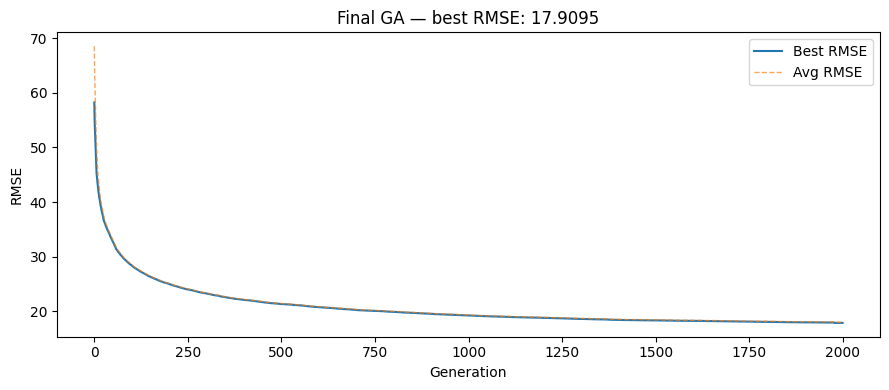

In [22]:
plot_fitness_history(
    history,
    avg_history,
    title=f"Final GA — best RMSE: {history[-1]:.4f}",
)

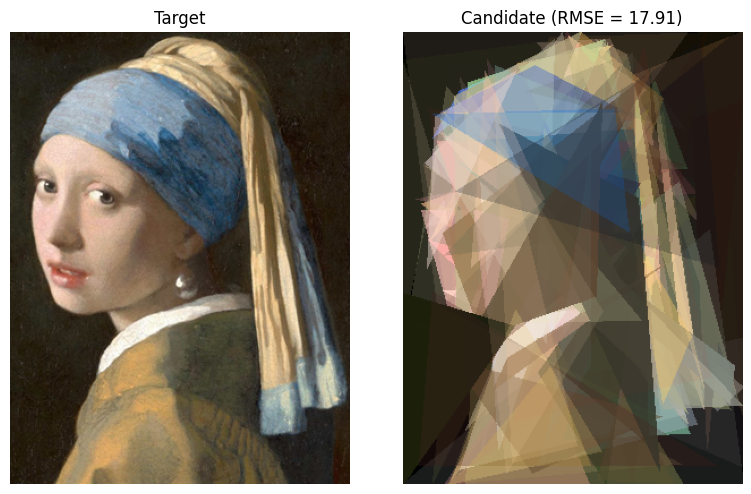

In [20]:
best_sol.show()

somehow save best solution

# <span id="chapter8" style="color:#86A3BC;">8. Fitness Sharing</span>

## <span id="chapter8.1" style="color:#86A3BC;">8.1. Statistical Comparison</span>

We compare standard tournament selection against the `AutomaticFitnessSharingSelection` to see if fitness sharing improves the final results.

In [ ]:
# fitness_sharing_statistical_comparison = run_ga_statistical_comparison(
#     "selection_function",
#     [
#         lambda p: tournament_selection(p, tournament_size=10),
#         AutomaticFitnessSharingSelection(
#             sigma_share=25.0,
#             alpha=1.0,
#             selection_function=lambda p: tournament_selection(p, tournament_size=10)
#         )
#     ],
#     return_diversity=True,
#     diversity_interval=10 # calculate diversity metrics every 10 epochs
# )


Starting statistical comparison: 60 GA runs, 600,000 total evaluations



Progress: 100%|██████████| 600000/600000 [15:46<00:00, 634.17 evaluation/s]


In [ ]:
# save_statistical_results(
#     fitness_sharing_statistical_comparison,
#     "results/fitness_sharing_statistical_comparison.pkl"
# )

In [205]:
fitness_sharing_statistical_comparison = load_statistical_results("results/fitness_sharing_statistical_comparison.pkl")

In [206]:
plot_statistical_comparison_interactive(
    fitness_sharing_statistical_comparison,
    labels=["Tournament (size 10)", "Fitness Sharing"]
)

In [209]:
run_multi_group_statistical_test(
    fitness_sharing_statistical_comparison,
    names=["Tournament (size 10)", "Advanced Fitness Sharing"]
)

=== Normality Checks (Shapiro-Wilk) ===
  - Tournament (size 10)           p-value: 0.6221 (Normal: True)
  - Advanced Fitness Sharing       p-value: 0.3506 (Normal: True)

=== Omnibus Statistical Test ===
All groups are approximately normal. Running One-way ANOVA...
Omnibus test used: One-way ANOVA
p-value: 0.624299

=== Summary Statistics ===
  - Tournament (size 10)           Mean: 36.2580 | Median: 36.0772 | Std: 1.2136
  - Advanced Fitness Sharing       Mean: 36.1074 | Median: 35.8691 | Std: 1.1139

Omnibus test is NOT statistically significant (p >= alpha).
No post-hoc pairwise comparisons will be performed.


In [208]:
plot_diversity_statistical_comparison_interactive(
    fitness_sharing_statistical_comparison,
    labels=["Tournament (size 10)", "Advanced Fitness Sharing"]
)

## <span id="chapter8.2" style="color:#86A3BC;">8.2. Final Run</span>

In [192]:
selection_with_fitness_sharing = AutomaticFitnessSharingSelection(
    sigma_share=25.0,
    alpha=1.0,
    selection_function=lambda p: tournament_selection(p, tournament_size=10)
)

In [194]:
best_sharing2, hist_sharing2, avg_hist_sharing2 = genetic_algorithm(
    solution_class=TriangleSolution,
    population_size=200,
    n_generations=8000,
    selection_function=selection_with_fitness_sharing,
    generation_callback=GenerationCounterCallback(selection_with_fitness_sharing),
    crossover_function=uniform_crossover,
    mutation_function=lambda i, m: triangle_gaussian_mutation(i, m, sigma_vertex=5, sigma_colour=20),
    crossover_rate=0.9,
    mutation_rate=0.01,
    mutation_rate_decay=1e-4,
    elitism_n=2,
    seed=33
)

Gen    0 | best RMSE: 54.9949 | avg RMSE: 63.1814 | mut rate: 0.01000
Gen   50 | best RMSE: 36.5813 | avg RMSE: 36.8435 | mut rate: 0.00995
Gen  100 | best RMSE: 31.9574 | avg RMSE: 32.1016 | mut rate: 0.00990
Gen  150 | best RMSE: 29.5922 | avg RMSE: 29.7511 | mut rate: 0.00985
Gen  200 | best RMSE: 27.9972 | avg RMSE: 28.1120 | mut rate: 0.00980
Gen  250 | best RMSE: 26.5071 | avg RMSE: 26.6370 | mut rate: 0.00975
Gen  300 | best RMSE: 25.2700 | avg RMSE: 25.3775 | mut rate: 0.00970
Gen  350 | best RMSE: 24.3151 | avg RMSE: 24.4210 | mut rate: 0.00966
Gen  400 | best RMSE: 23.7214 | avg RMSE: 23.8216 | mut rate: 0.00961
Gen  450 | best RMSE: 23.2983 | avg RMSE: 23.4099 | mut rate: 0.00956
Gen  500 | best RMSE: 22.8901 | avg RMSE: 22.9711 | mut rate: 0.00951
Gen  550 | best RMSE: 22.6024 | avg RMSE: 22.6727 | mut rate: 0.00946
Gen  600 | best RMSE: 22.2482 | avg RMSE: 22.3529 | mut rate: 0.00942
Gen  650 | best RMSE: 21.9421 | avg RMSE: 22.0294 | mut rate: 0.00937
Gen  700 | best RMSE

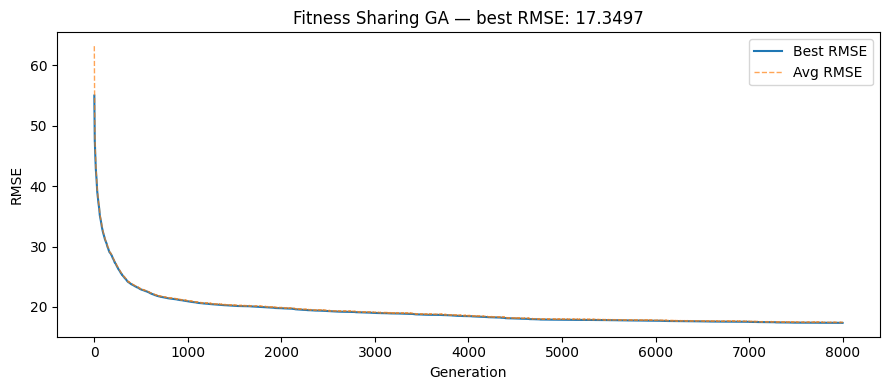

In [197]:
plot_fitness_history(
    hist_sharing2,
    avg_hist_sharing2,
    title=f"Fitness Sharing GA — best RMSE: {hist_sharing2[-1]:.4f}",
)

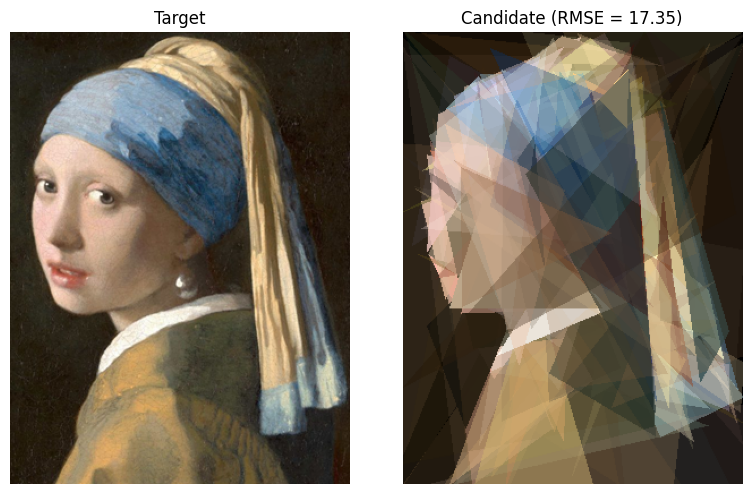

In [198]:
best_sharing2.show()

## old run

In [ ]:
diversity_log = []

def diversity_callback(gen, population):
    if gen % 10 == 0:   # every 10 gens to keep overhead low
        diversity_log.append(
            {'gen': gen, **population_diversity_report(population)}
        )

In [117]:
selector_test2 = AdvancedFitnessSharingSelection(
    sigma_share=0.05, # was 0.15 — tighter niches, less aggressive penalisation
    alpha=1.0,
    tournament_size=10,
)

In [118]:
VERMEER_SUPER_PARAMS = dict(
    solution_class=TriangleSolution,
    population_size=200,
    n_generations=8000,
    selection_function=selector_test2,
    generation_callback=GenerationCounterCallback(selector_test2),
    crossover_function=uniform_crossover,
    mutation_function=lambda i, m: triangle_gaussian_mutation(i, m, sigma_vertex=5, sigma_colour=20),
    crossover_rate=0.9,
    mutation_rate=0.01,
    mutation_rate_decay=1e-4,
    elitism_n=2
)

best_sharing, hist_sharing, avg_hist_sharing = genetic_algorithm(**VERMEER_SUPER_PARAMS)

Gen    0 | best RMSE: 55.0072 | avg RMSE: 63.4891 | mut rate: 0.01000
Gen   50 | best RMSE: 37.4677 | avg RMSE: 37.7836 | mut rate: 0.00995
Gen  100 | best RMSE: 33.7060 | avg RMSE: 33.9681 | mut rate: 0.00990
Gen  150 | best RMSE: 31.5060 | avg RMSE: 31.7503 | mut rate: 0.00985
Gen  200 | best RMSE: 29.5502 | avg RMSE: 29.7698 | mut rate: 0.00980
Gen  250 | best RMSE: 28.0635 | avg RMSE: 28.2691 | mut rate: 0.00975
Gen  300 | best RMSE: 27.1468 | avg RMSE: 27.3151 | mut rate: 0.00970
Gen  350 | best RMSE: 26.5914 | avg RMSE: 26.7787 | mut rate: 0.00966
Gen  400 | best RMSE: 25.9919 | avg RMSE: 26.1622 | mut rate: 0.00961
Gen  450 | best RMSE: 25.4417 | avg RMSE: 25.5595 | mut rate: 0.00956
Gen  500 | best RMSE: 25.1902 | avg RMSE: 25.3412 | mut rate: 0.00951
Gen  550 | best RMSE: 24.7828 | avg RMSE: 24.9614 | mut rate: 0.00946
Gen  600 | best RMSE: 24.6350 | avg RMSE: 24.7883 | mut rate: 0.00942
Gen  650 | best RMSE: 24.4266 | avg RMSE: 24.5994 | mut rate: 0.00937
Gen  700 | best RMSE

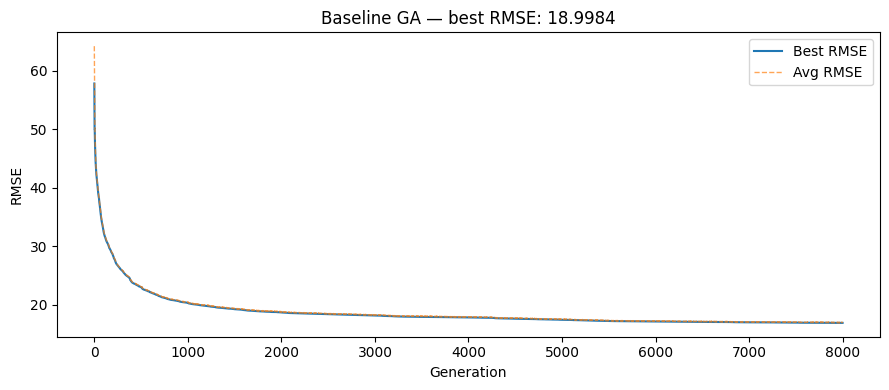

In [120]:
plot_fitness_history(
    history,
    avg_history,
    title=f"Baseline GA — best RMSE: {hist_sharing[-1]:.4f}",
)

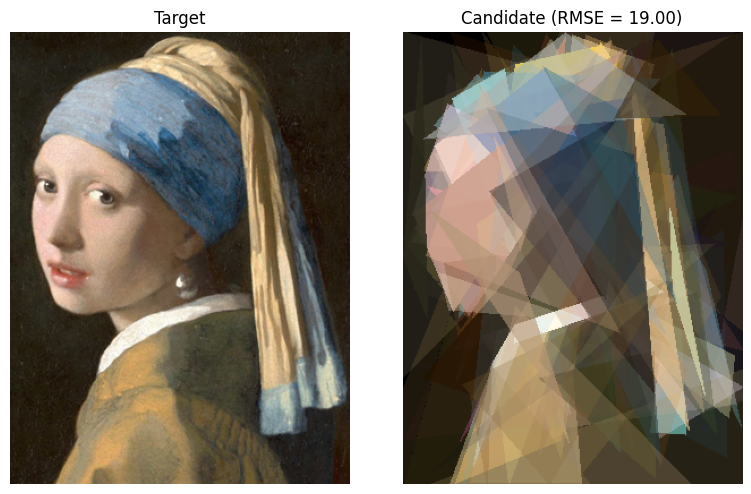

In [119]:
best_sharing.show()

# <span id="chapter9" style="color:#86A3BC;">9. Hill Climbing for Local Search</span>

<p><a href="#toc" style="color:#86A3BC;">Back to Table of Contents</a></p>

adicionar markdowns

In [114]:
ga_rmse_before_hc = get_fitness(best_sol)

best_polished_solution, hc_log, hc_evals = hill_climbing(
    solution=best_sol,
    max_iterations=500, # still improving, give it more budget
    delta_vertex=7.0, # start where it actually worked, skip the wasted iter 1
    delta_colour=6.0, # same reasoning
    decay_factor=0.7, # slower decay, stays at productive scale longer
    min_delta=0.05, # allow finer refinement at the end
    trials_per_iteration=2,# 2 perturbations per triangle per pass
    verbose=True,
)

print(f"\nGA final RMSE : {ga_rmse_before_hc:.4f}")
print(f"HC final RMSE : {best_polished_solution.fitness():.4f}")
improvement = ga_rmse_before_hc - best_polished_solution.fitness()
print(f"Improvement : {improvement:.4f}  ({improvement / ga_rmse_before_hc * 100:.2f} %)")
print(f"Evaluations : {hc_evals:,}")

Hill Climbing start — RMSE: 16.8944 | delta_v=7.00, delta_c=6.00
  Iter   1 | RMSE: 16.8897 | improvements:    2 | delta_v=7.000, delta_c=6.000
  Iter   2 | RMSE: 16.8867 | improvements:    3 | delta_v=7.000, delta_c=6.000
  Iter   3 | RMSE: 16.8820 | improvements:    2 | delta_v=7.000, delta_c=6.000
  Iter   4 | RMSE: 16.8816 | improvements:    1 | delta_v=7.000, delta_c=6.000
  Iter   5 | RMSE: 16.8816 | improvements:    0 | delta_v=7.000, delta_c=6.000
  Iter   6 | RMSE: 16.8813 | improvements:    1 | delta_v=4.900, delta_c=4.200
  Iter   7 | RMSE: 16.8797 | improvements:    2 | delta_v=4.900, delta_c=4.200
  Iter   8 | RMSE: 16.8786 | improvements:    3 | delta_v=4.900, delta_c=4.200
  Iter   9 | RMSE: 16.8767 | improvements:    2 | delta_v=4.900, delta_c=4.200
  Iter  10 | RMSE: 16.8738 | improvements:    3 | delta_v=4.900, delta_c=4.200
  Iter  11 | RMSE: 16.8692 | improvements:    5 | delta_v=4.900, delta_c=4.200
  Iter  12 | RMSE: 16.8621 | improvements:    3 | delta_v=4.900, d

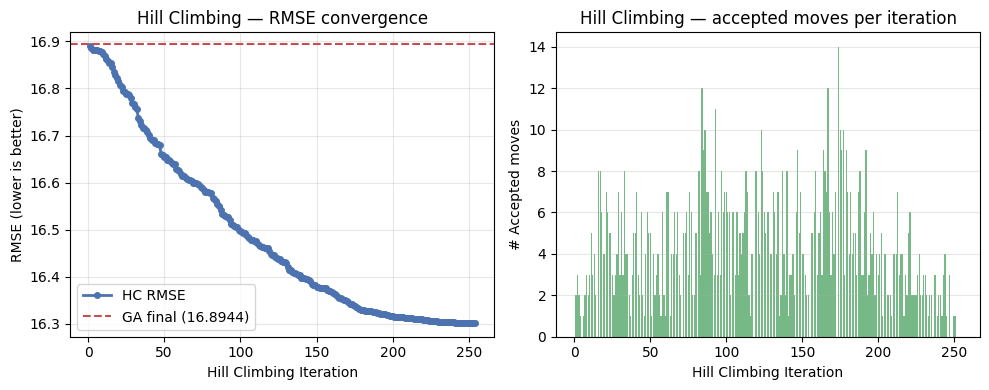

In [157]:
plot_hill_climbing_log(hc_log, ga_final_rmse=ga_rmse_before_hc)

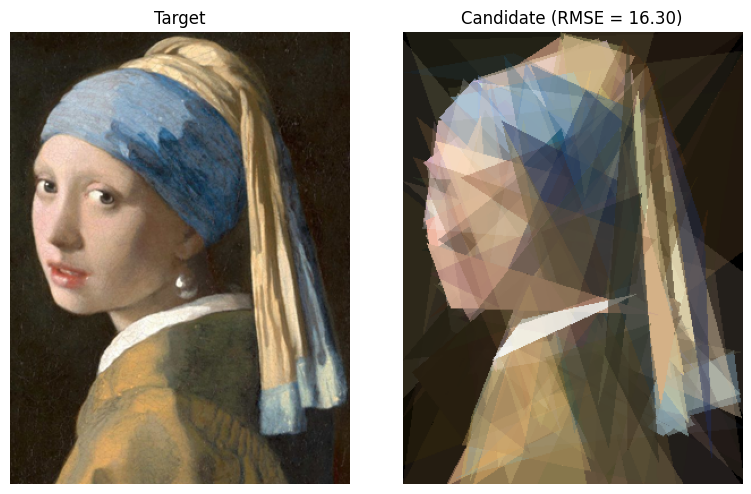

In [158]:
best_polished_solution.show()

In [195]:
# Save the 100-triangle gene representation to a file
np.save("best_polished_representation.npy", best_polished_solution.representation)
print("Saved best polished solution genotype representation.")

Saved best polished solution genotype representation.


# <span id="chapter10" style="color:#86A3BC;">10. Challenge 1 - Perceptual Fitness (CIEDE2000)</span>

RGB RMSE doesn't really capture how we perceive colour. The eye isn't equally sensitive across the colour gamut, so for Challenge 1 we swap the fitness for **mean CIEDE2000 (ΔE2000)** in CIELAB, a space built to be perceptually uniform.

This is done as a subclass of `TriangleSolution` ([PerceptualTriangleSolution](scripts/perceptual_fitness.py#L72)) that only overrides `fitness()`. The GA, operators, and caching all stay the same.

## <span id="chapter10.1" style="color:#86A3BC;">10.1. Statistical Comparison - RMSE vs Perceptual</span>

We use `run_ga_statistical_comparison` with `solution_class` as the parameter being varied. **Paired seeds** (`base_seed + i` for run *i*) mean both GAs start from the same initial population, so the fitness function is the only thing differing.

RMSE and ΔE2000 are on different scales, so the convergence plot uses `subplots=True` for separate y-axes. The cross-evaluation below puts both GAs on the same scale.

In [ ]:
# perceptual_statistical_comparison = run_ga_statistical_comparison(
#     "solution_class",
#     [TriangleSolution, PerceptualTriangleSolution],
#     n_runs=30,
#     base_seed=1000,
#     return_representations=True,
# )


Starting statistical comparison: 60 GA runs, 600,000 total evaluations



Progress: 100%|██████████| 600000/600000 [1:09:37<00:00, 143.63 evaluation/s]


In [ ]:
# save_statistical_results(
#     perceptual_statistical_comparison,
#     "results/perceptual_statistical_comparison.pkl"
# )

In [ ]:
perceptual_statistical_comparison = load_statistical_results(
    "results/perceptual_statistical_comparison.pkl"
)

In [109]:
plot_statistical_comparison_interactive(
    perceptual_statistical_comparison,
    labels=["RMSE", "Perceptual (CIEDE2000)"],
    title="Convergence — RMSE vs Perceptual GA (paired seeds)",
    ylabel=["Best RMSE (lower is better)", "Best ΔE2000 (lower is better)"],
    subplots=True,
)

## <span id="chapter10.2" style="color:#86A3BC;">10.2. Cross-Evaluation</span>

Each GA's `best_per_run` is on its own scale, so we can't compare them directly. We reconstruct every best solution and score it on both metrics using `rmse_score` and `perceptual_score`.

In [189]:
cross_eval = cross_evaluate_results(
    perceptual_statistical_comparison,
    score_functions={"RMSE": rmse_score, "ΔE2000": perceptual_score},
    solution_classes=[TriangleSolution, PerceptualTriangleSolution],
)

cross_eval_table(cross_eval, labels=["RGB-RMSE GA", "Perceptual GA"])


GA (optimised for)                           RMSE                 ΔE2000
------------------------------------------------------------------------
RGB-RMSE GA                   39.406 ± 1.268     19.231 ± 0.750 
Perceptual GA                 44.718 ± 1.618     17.298 ± 0.660 
------------------------------------------------------------------------


In [183]:
keys = list(cross_eval.keys())

print("RMSE:")
run_statistical_test(
    cross_eval[keys[0]]["RMSE"],
    cross_eval[keys[1]]["RMSE"],
    name_a="RGB-RMSE GA",
    name_b="Perceptual GA",
    paired=True,
)

print("\nΔE2000:")
run_statistical_test(
    cross_eval[keys[0]]["ΔE2000"],
    cross_eval[keys[1]]["ΔE2000"],
    name_a="RGB-RMSE GA",
    name_b="Perceptual GA",
    paired=True,
)

RMSE:
RGB-RMSE GA normality p-value: 0.1858
Perceptual GA normality p-value: 0.3213

Welch t-test
p-value: 0.0000

RGB-RMSE GA mean final RMSE: 39.4063
Perceptual GA mean final RMSE: 44.7184
Difference is statistically significant.

ΔE2000:
RGB-RMSE GA normality p-value: 0.4464
Perceptual GA normality p-value: 0.7239

Welch t-test
p-value: 0.0000

RGB-RMSE GA mean final RMSE: 19.2309
Perceptual GA mean final RMSE: 17.2982
Difference is statistically significant.


## <span id="chapter10.3" style="color:#86A3BC;">10.3. Visual Comparison</span>

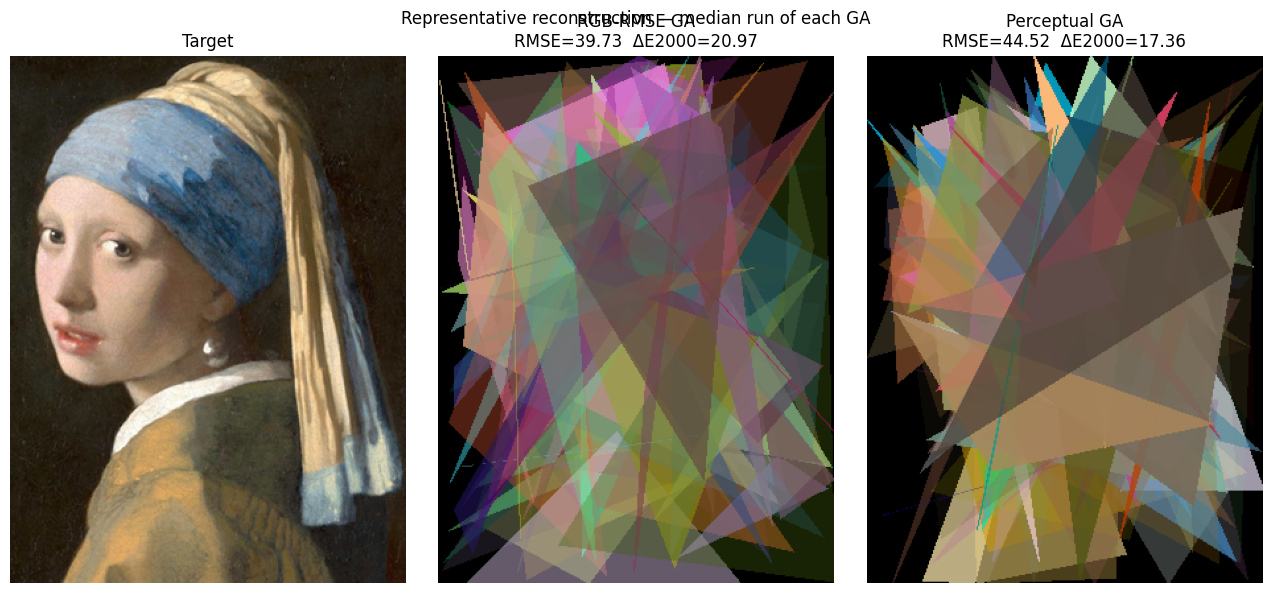

In [184]:
plot_image_comparison(
    perceptual_statistical_comparison,
    solution_classes=[TriangleSolution, PerceptualTriangleSolution],
    score_functions={"RMSE": rmse_score, "ΔE2000": perceptual_score},
    labels=["RGB-RMSE GA", "Perceptual GA"],
)

## <span id="chapter10.4" style="color:#86A3BC;">10.4. Individual Perceptual GA Run</span>

One longer run with the tuned config to get a decent perceptual reconstruction.

In [115]:
set_perceptual_target(target_arr)

best_perceptual, history_perceptual, avg_history_perceptual = genetic_algorithm(
    solution_class=PerceptualTriangleSolution,
    population_size=200,
    n_generations=2000,
    selection_function=lambda p: tournament_selection(p, tournament_size=10),
    crossover_function=uniform_crossover,
    mutation_function=triangle_gaussian_mutation,
    crossover_rate=0.9,
    mutation_rate=0.01,
    mutation_rate_decay=1e-4,
    elitism_n=2
)
print(f"Best ΔE2000: {best_perceptual.fitness():.4f}")
print(f"Cross-eval RMSE: {rmse_score(best_perceptual):.4f}")

Gen    0 | best ΔE2000: 26.5217 | avg ΔE2000: 29.7673 | mut rate: 0.01000
Gen   50 | best ΔE2000: 16.3377 | avg ΔE2000: 16.5186 | mut rate: 0.00995
Gen  100 | best ΔE2000: 14.0447 | avg ΔE2000: 14.1282 | mut rate: 0.00990
Gen  150 | best ΔE2000: 12.4809 | avg ΔE2000: 12.5503 | mut rate: 0.00985
Gen  200 | best ΔE2000: 11.4442 | avg ΔE2000: 11.5033 | mut rate: 0.00980
Gen  250 | best ΔE2000: 10.7557 | avg ΔE2000: 10.8049 | mut rate: 0.00975
Gen  300 | best ΔE2000: 10.1791 | avg ΔE2000: 10.2216 | mut rate: 0.00970
Gen  350 | best ΔE2000: 9.7576 | avg ΔE2000: 9.7900 | mut rate: 0.00966
Gen  400 | best ΔE2000: 9.5149 | avg ΔE2000: 9.5448 | mut rate: 0.00961
Gen  450 | best ΔE2000: 9.2944 | avg ΔE2000: 9.3208 | mut rate: 0.00956
Gen  500 | best ΔE2000: 9.0738 | avg ΔE2000: 9.1059 | mut rate: 0.00951
Gen  550 | best ΔE2000: 8.9100 | avg ΔE2000: 8.9456 | mut rate: 0.00946
Gen  600 | best ΔE2000: 8.7582 | avg ΔE2000: 8.7940 | mut rate: 0.00942
Gen  650 | best ΔE2000: 8.6361 | avg ΔE2000: 8.659

In [186]:
np.save("best_perceptual_representation.npy", best_perceptual.representation)
print("saved.")

saved.


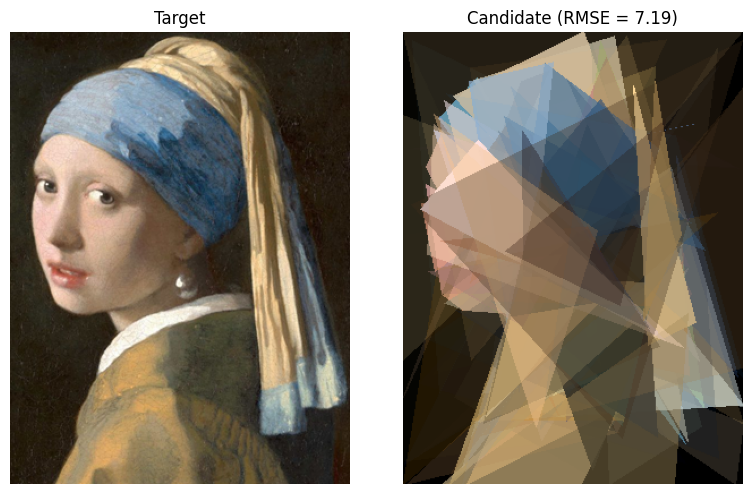

In [185]:
best_perceptual.show()

# <span id="chapter11" style="color:#86A3BC;">11. Save Best Result</span>

<p><a href="#toc" style="color:#86A3BC;">Back to Table of Contents</a></p>

In [210]:
out_path = "best_result.png"
best_polished_solution.get_image().save(out_path)
print(f"Saved best candidate to: {out_path}")

Saved best candidate to: best_result.png
